<a href="https://colab.research.google.com/github/09StevenG/2022-ii-tutorial-git-repo-ejemplo/blob/main/Interpolacion_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [174]:
import rasterio

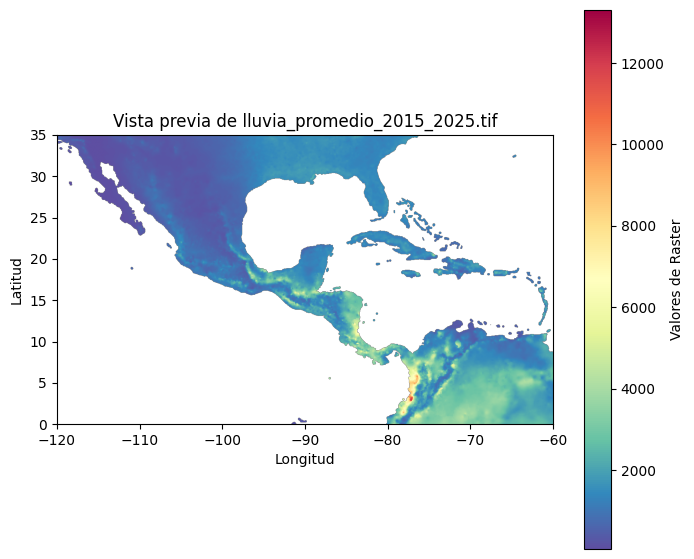

In [175]:
#mostrar raster de climatologia
import rasterio
import matplotlib.pyplot as plt

url_raster = "https://github.com/navilaufm/geodata/raw/refs/heads/main/catie/lluvia_promedio_2015_2025.tif"

with rasterio.open(url_raster) as src:
    raster_data = src.read(1, masked=True)
    spatial_extent = (
        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top
    )

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(raster_data, extent=spatial_extent, cmap="Spectral_r")
plt.colorbar(im, ax=ax, label="Valores de Raster")
ax.set_title("Vista previa de lluvia_promedio_2015_2025.tif")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.show()

### Extracción de valores del Raster en los puntos de las estaciones

In [176]:
# Usaremos el rasterio cargado previamente para extraer los valores de climatología
coords = [(geom.x, geom.y) for geom in estaciones.geometry]

with rasterio.open(url_raster) as src:
    # Extraemos el valor del primer canal del raster para cada coordenada
    valores_extraidos = [val[0] for val in src.sample(coords)]

# Creamos una copia del DataFrame original para trabajar con los nuevos valores de lluvia
estaciones_clima = estaciones.copy()
estaciones_clima['clima_mm'] = valores_extraidos

# Filtrar posibles valores fuera de rango o nulos (no-data)
estaciones_clima = estaciones_clima.dropna(subset=['clima_mm'])
estaciones_clima = estaciones_clima[estaciones_clima['clima_mm'] > -9999]

# Mostrar el resultado final
display(estaciones_clima[['nombre', 'latitud', 'longitud', 'clima_mm']].head())

,nombre,latitud,longitud,clima_mm
0,21 de Octubre,14.1833,-87.17445,1461.322998
1,Acajutla Puerto Nuevo,13.5678,-89.84720,1755.180908
2,Aeropuerto De Ilopango,13.6858,-89.11860,1704.908813
3,Agua Caliente,14.5800,-87.15250,1307.167725
4,"Alameda Icta, Chimaltenango",14.6338,-90.80330,1115.221558


```markdown
# PROCESAMIENTO ESPACIAL DE CLIMATOLOGÍA PROMEDIO (2015-2025)

Este cuaderno contiene el flujo completo desde cero para la interpolación espacial de la precipitación promedio obtenida a través de la extracción de valores del raster de climatología en las estaciones meteorológicas.
```

```markdown
## 1. Configuración de Datos Climatológicos
Consolidamos el GeoDataFrame de estaciones utilizando los valores de lluvia promedio anual extraídos del raster anterior (`clima_mm`).
```

In [177]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.transform import from_origin
import shapely
from shapely import contains_xy

# Consolidamos el GeoDataFrame con la lluvia climatológica extraída
datos_clima = estaciones_clima.copy()
geom_clima = datos_clima.geometry
z_clima = datos_clima.clima_mm.values
x_clima = datos_clima.longitud.values
y_clima = datos_clima.latitud.values

print(f"Número de estaciones listas para análisis: {len(datos_clima)}")
display(datos_clima[['nombre', 'longitud', 'latitud', 'clima_mm']].head())

Número de estaciones listas para análisis: 123


,nombre,longitud,latitud,clima_mm
0,21 de Octubre,-87.17445,14.1833,1461.322998
1,Acajutla Puerto Nuevo,-89.84720,13.5678,1755.180908
2,Aeropuerto De Ilopango,-89.11860,13.6858,1704.908813
3,Agua Caliente,-87.15250,14.5800,1307.167725
4,"Alameda Icta, Chimaltenango",-90.80330,14.6338,1115.221558


```markdown
## 2. Construcción de la Malla Espacial de Estimación
Definimos los límites geográficos basados en la frontera nacional de Centroamérica y generamos los nodos de la cuadrícula de estimación.
```

In [178]:
RES = 0.05  # Resolución en grados decimales

# Límites de la frontera adaptados
xmin, ymin, xmax, ymax = frontera.total_bounds
xmin, ymin = np.floor(xmin / RES) * RES, np.floor(ymin / RES) * RES
xmax, ymax = np.ceil(xmax / RES) * RES, np.ceil(ymax / RES) * RES

# Crear grilla matricial
xs = np.arange(xmin, xmax, RES) + RES / 2
ys = np.arange(ymax, ymin, -RES) - RES / 2
xi, yi = np.meshgrid(xs, ys)
ny, nx = xi.shape

# Enmascaramiento para áreas de tierra firme
tierra = contains_xy(frontera.union_all(), xi, yi)
puntos_malla = gpd.GeoSeries(gpd.points_from_xy(xi.ravel(), yi.ravel()), crs="EPSG:4326")

print(f"Malla construida: {ny} filas x {nx} columnas ({nx * ny} puntos)")
print(f"Celdas de interés (Tierra firme): {tierra.sum()}")

Malla construida: 260 filas x 302 columnas (78520 puntos)
Celdas de interés (Tierra firme): 17201


```markdown
## 3. Definición de Algoritmos de Interpolación
Implementamos las clases y funciones de distancia para realizar las aproximaciones espaciales por **Vecino Más Cercano** y **Ponderación Inversa a la Distancia (IDW)**.
```

In [179]:
def distance_matrix(estaciones, puntos):
    columna = np.asarray(estaciones)[:, None]
    fila = np.asarray(puntos)[None, :]
    return shapely.distance(columna, fila)

def vecino_cercano(estaciones, z, puntos):
    dist = distance_matrix(estaciones, puntos)
    mas_cercana = dist.argmin(axis=0)
    return z[mas_cercana]

def simple_idw(estaciones, z, puntos, potencia=2):
    dist = distance_matrix(estaciones, puntos)
    # Evitar divisiones por cero sumando un epsilon muy pequeño
    eps = 1e-12
    pesos = (dist + eps) ** (-potencia)
    pesos /= pesos.sum(axis=0)
    return np.dot(pesos.T, z)

```markdown
## 4. Validación Cruzada para IDW
Analizamos de manera iterativa distintos coeficientes de potencia de fricción de la distancia para determinar el que produce menores desviaciones estadísticas (RMSE).
```

In [180]:
def validacion_cruzada_clima(potencia, puntos=geom_clima):
    errores = []
    for i in range(len(z_clima)):
        otras = np.arange(len(z_clima)) != i
        estimado = simple_idw(puntos.iloc[otras], z_clima[otras], puntos.iloc[[i]], potencia)[0]
        errores.append(estimado - z_clima[i])
    return np.sqrt(np.mean(np.square(errores)))

potencias_prueba = [1, 1.5, 2, 2.5, 3, 3.2, 3.5, 3.7, 4, 4.5, 5, 6]
resultados_cv = pd.DataFrame({
    "potencia": potencias_prueba,
    "RMSE_mm": [round(validacion_cruzada_clima(p), 2) for p in potencias_prueba]
})

P_OPTIMA_CLIMA = float(resultados_cv.loc[resultados_cv.RMSE_mm.idxmin(), "potencia"])
print(f"Potencia óptima seleccionada: {P_OPTIMA_CLIMA}")
display(resultados_cv)

Potencia óptima seleccionada: 3.0


,potencia,RMSE_mm
0,1.0,713.81
1,1.5,651.44
2,2.0,621.94
3,2.5,612.62
4,3.0,612.08
5,3.2,613.10
6,3.5,615.44
7,3.7,617.41
8,4.0,620.86
9,4.5,627.49


```markdown
## 5. Modelado, Interpolación y Visualización de Mapas
Ejecutamos la interpolación en toda la grilla para ambos algoritmos y mapeamos los resultados junto a sus respectivas curvas isoyetas.
```

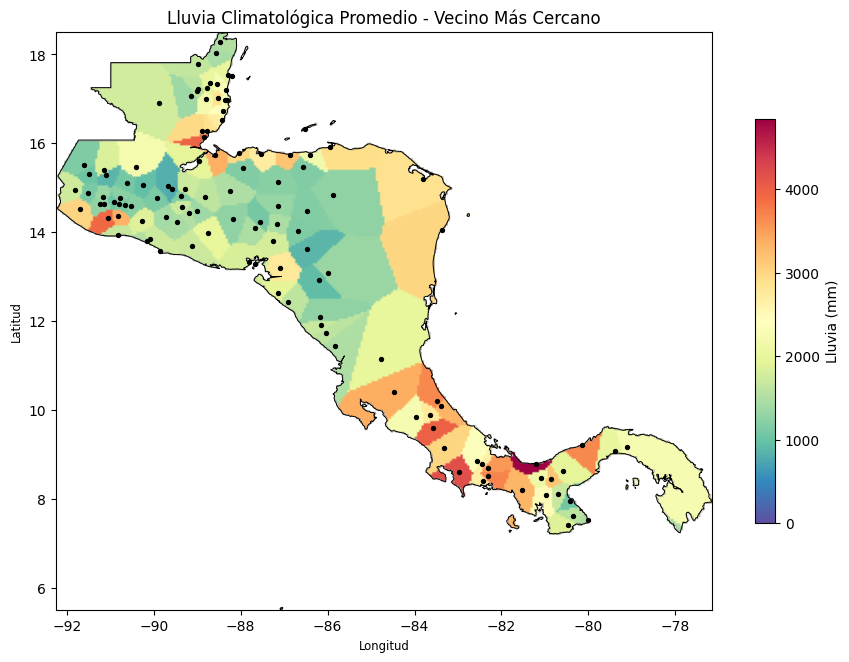

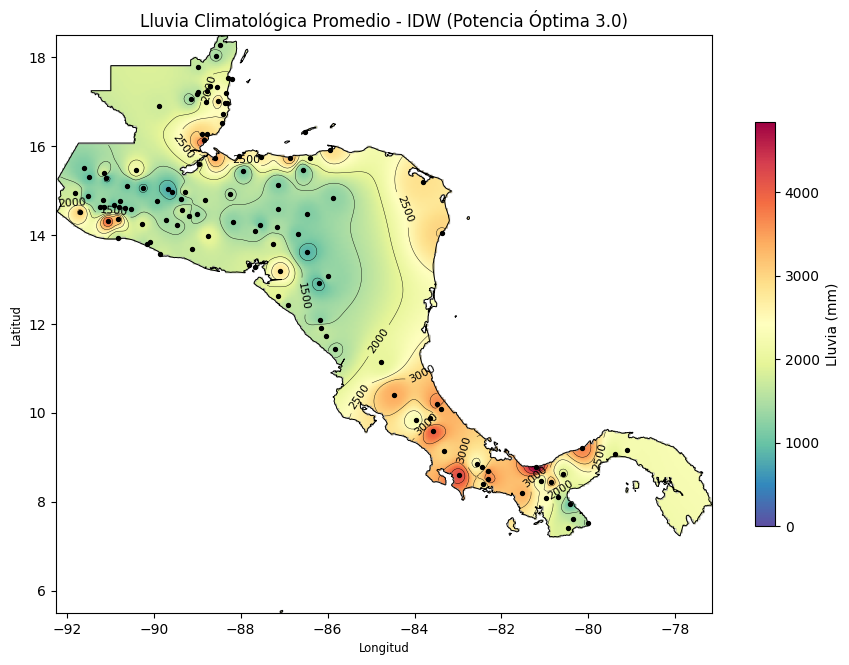

In [181]:
# 1. Generación de las grillas espaciales continuas
grilla_vecino_clima = vecino_cercano(geom_clima, z_clima, puntos_malla).reshape(ny, nx)
grilla_idw_final = simple_idw(geom_clima, z_clima, puntos_malla, potencia=P_OPTIMA_CLIMA).reshape(ny, nx)

# Función para graficar los mapas
def plot_mapa_clima(grilla, titulo, max_valor):
    fig, ax = plt.subplots(figsize=(11, 7.5))
    im = ax.imshow(np.where(tierra, grilla, np.nan), extent=(xmin, xmax, ymin, ymax), cmap="Spectral_r", vmin=0, vmax=max_valor)
    frontera.plot(ax=ax, color="none", edgecolor="black", linewidth=0.7)
    ax.scatter(x_clima, y_clima, color="black", s=8, label="Estaciones")
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    plt.colorbar(im, ax=ax, label="Lluvia (mm)", shrink=0.7)
    return ax

# Mapa 1: Vecino Más Cercano
plot_mapa_clima(grilla_vecino_clima, "Lluvia Climatológica Promedio - Vecino Más Cercano", int(z_clima.max()))
plt.show()

# Mapa 2: IDW Óptimo con Isoyetas
ax_idw = plot_mapa_clima(grilla_idw_final, f"Lluvia Climatológica Promedio - IDW (Potencia Óptima {P_OPTIMA_CLIMA})", int(z_clima.max()))
niveles_contorno = list(range(500, int(z_clima.max()), 500))
cs = ax_idw.contour(xi, yi, np.where(tierra, grilla_idw_final, np.nan), levels=niveles_contorno, colors="black", linewidths=0.3)
ax_idw.clabel(cs, fmt="%d", fontsize=8)
plt.show()

```markdown
## 6. Exportación a Formato GeoTIFF
Guardamos los mapas resultantes como archivos raster estándar en formato TIF.
```

In [182]:
def exportar_clima_geotiff(nombre_archivo, matriz):
    salida = np.where(tierra, matriz, -9999).astype("float32")
    with rasterio.open(nombre_archivo, "w", driver="GTiff", height=ny, width=nx, count=1, dtype="float32",
                       crs="EPSG:4326", transform=from_origin(xmin, ymax, RES, RES), nodata=-9999) as dst:
        dst.write(salida, 1)
    print(f"Archivo raster exportado exitosamente: {nombre_archivo}")

exportar_clima_geotiff("climatologia_vecino.tif", grilla_vecino_clima)
exportar_clima_geotiff("climatologia_idw_optima.tif", grilla_idw_final)

Archivo raster exportado exitosamente: climatologia_vecino.tif
Archivo raster exportado exitosamente: climatologia_idw_optima.tif


### Validación Cruzada para buscar la potencia óptima con los nuevos datos de climatología

In [183]:
# Definimos las variables para el nuevo análisis espacial
geom_clima = estaciones_clima.geometry
z_clima = estaciones_clima.clima_mm.values

def validacion_cruzada_clima(potencia, puntos=geom_clima):
    errores = []
    for i in range(len(z_clima)):
        otras = np.arange(len(z_clima)) != i                     # todas las estaciones excepto la estación 'i'
        estimado = simple_idw(puntos.iloc[otras], z_clima[otras], puntos.iloc[[i]], potencia)[0]
        errores.append(estimado - z_clima[i])
    return np.sqrt(np.mean(np.square(errores)))                  # Error típico RMSE

# Probar una serie de potencias posibles para IDW
potencias_clima = [1, 1.5, 2, 2.5, 3, 3.2, 3.5, 3.7, 4, 4.5, 5, 6]
tabla_potencias_clima = pd.DataFrame({
    "potencia": potencias_clima,
    "error_tipico_mm": [round(validacion_cruzada_clima(p), 1) for p in potencias_clima]
})

P_OPTIMA_CLIMA = float(tabla_potencias_clima.loc[tabla_potencias_clima.error_tipico_mm.idxmin(), "potencia"])
print(f"Potencia óptima identificada para climatología: {P_OPTIMA_CLIMA:g}")
display(tabla_potencias_clima)

Potencia óptima identificada para climatología: 3


,potencia,error_tipico_mm
0,1.0,713.8
1,1.5,651.4
2,2.0,621.9
3,2.5,612.6
4,3.0,612.1
5,3.2,613.1
6,3.5,615.4
7,3.7,617.4
8,4.0,620.9
9,4.5,627.5


### Generación del Mapa de Interpolación Final para Climatología (IDW p = 3.0)

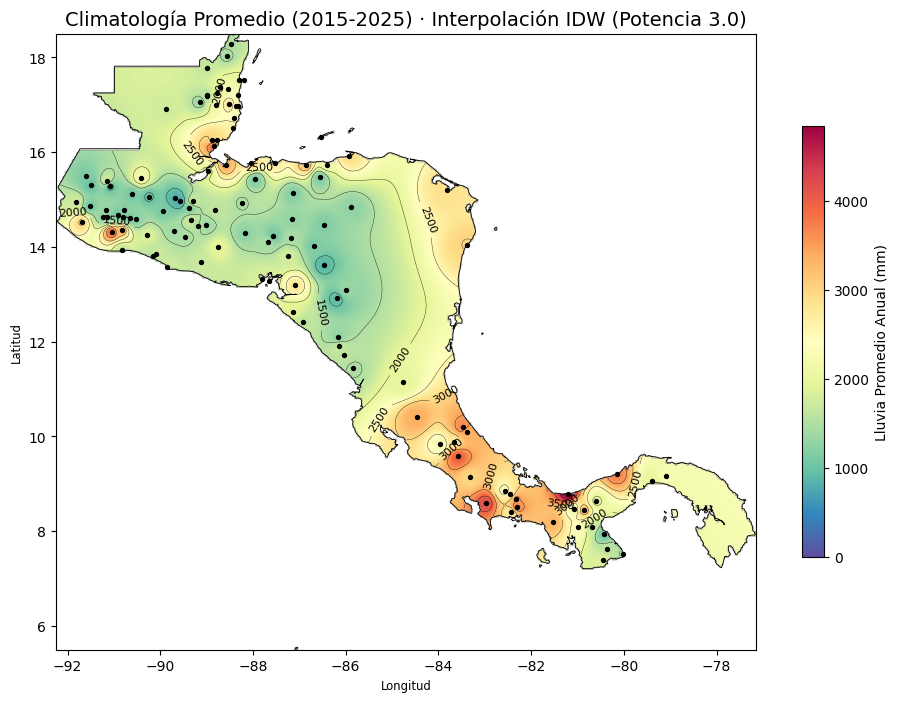

In [184]:
# Generar la grilla interpolada usando la potencia óptima calculada de 3.0
grilla_clima_final = simple_idw(geom_clima, z_clima, puntos_malla, potencia=3.0).reshape(ny, nx)

# Obtener el valor máximo para ajustar la escala de colores
max_valor = int(z_clima.max())

# Crear el gráfico final
fig, ax = plt.subplots(figsize=(12, 8))

# Mostrar la imagen interpolada enmascarada para tierra
im = ax.imshow(np.where(tierra, grilla_clima_final, np.nan),
               extent=(xmin, xmax, ymin, ymax),
               cmap="Spectral_r",
               vmin=0,
               vmax=max_valor)

# Graficar la frontera de Centroamérica
frontera.plot(ax=ax, color="none", edgecolor="black", linewidth=0.6)

# Mostrar los puntos de las estaciones climáticas
ax.scatter(x_clima, y_clima, color="black", s=8, label="Estaciones")

# Agregar curvas de nivel (isoyetas) cada 500 mm
niveles = list(range(500, max_valor, 500))
isoyetas_clima = ax.contour(xi, yi, np.where(tierra, grilla_clima_final, np.nan),
                            levels=niveles, colors="black", linewidths=0.25)
ax.clabel(isoyetas_clima, fmt="%d", fontsize=8)

# Configurar detalles del mapa
ax.set_title("Climatología Promedio (2015-2025) · Interpolación IDW (Potencia 3.0)", fontsize=14)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.colorbar(im, ax=ax, label="Lluvia Promedio Anual (mm)", shrink=0.7)

plt.show()

### Paso 3: Interpolación Final de Climatología con IDW

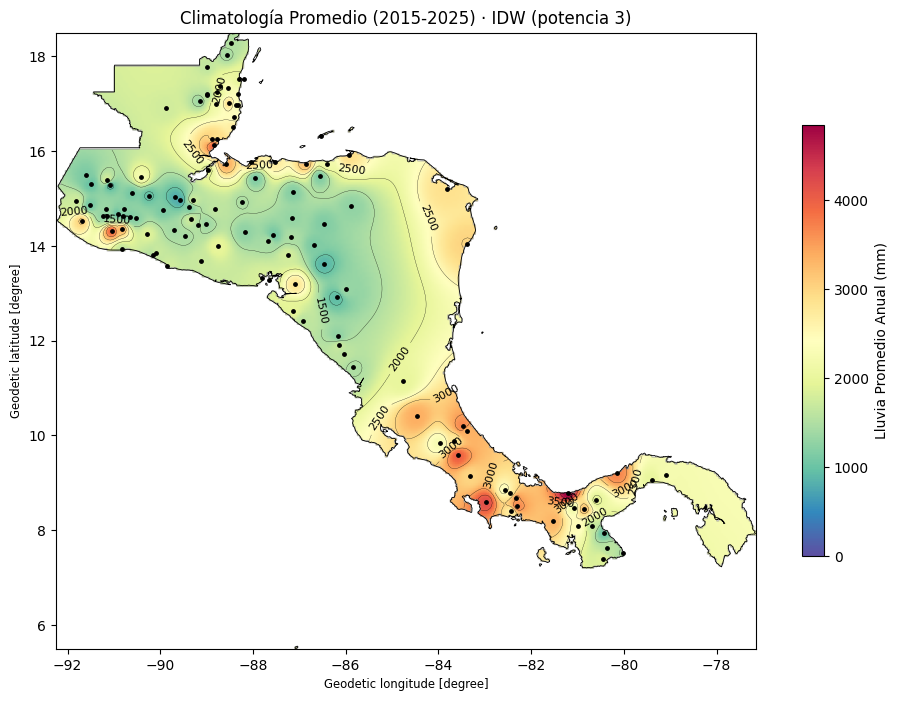

In [185]:
# Generar la grilla interpolada usando la potencia óptima encontrada (1.0)
grilla_clima_idw = simple_idw(geom_clima, z_clima, puntos_malla, potencia=P_OPTIMA_CLIMA).reshape(ny, nx)

# Redefinimos una función de mapa adaptada a los rangos de climatología promedio
x_clima, y_clima = estaciones_clima.longitud.values, estaciones_clima.latitud.values

def mapa_clima(matriz, titulo, ax=None, vmax=5000):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    im = ax.imshow(np.where(tierra, matriz, np.nan), extent=(xmin, xmax, ymin, ymax), cmap="Spectral_r", vmin=0, vmax=vmax)
    frontera.plot(ax=ax, color="none", edgecolor="black", linewidth=0.6)
    ax.scatter(x_clima, y_clima, color="black", s=6)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label="Lluvia Promedio Anual (mm)", shrink=0.7)
    return ax

# Graficar el resultado final de la interpolación de climatología promedio
max_valor = int(z_clima.max())
ax = mapa_clima(grilla_clima_idw, f"Climatología Promedio (2015-2025) · IDW (potencia {P_OPTIMA_CLIMA:g})", vmax=max_valor)

# Agregar curvas de nivel basadas en los valores del nuevo modelo
niveles = list(range(500, max_valor, 500))
isoyetas_clima = ax.contour(xi, yi, np.where(tierra, grilla_clima_idw, np.nan),
                            levels=niveles, colors="black", linewidths=0.2)
ax.clabel(isoyetas_clima, fmt="%d", fontsize=8)
plt.show()